In [1]:
!pip install pennylane pennylane-lightning -q

In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import torch
from scipy.stats import spearmanr
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEED = 42                     # master seed: split, first undersampling, first initialisation
SAMPLE_FRACTION = 1.0         # < 1.0 keeps a stratified fraction of the data, for fast experiments
N_QUBITS = 4                  # one PCA feature per qubit
FEATURE_MAP_REPS = 2          # repetitions of the ZZ feature map
ANSATZ_REPS = 3               # entangling layers of the ansatz: (ANSATZ_REPS + 1) * N_QUBITS * 2 parameters
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.05
SHOTS_PER_EXECUTION = 1024    # only used for the hardware cost ledger
NOISE_LEVELS = [0.001, 0.01, 0.05]                                   # depolarizing probability per gate
NATIVE_GATES = {"RX", "RY", "RZ", "Rot", "Hadamard", "CNOT", "CZ"}   # gate set of the noise model (Part 10)
SEEDS = [0, 1, 2, 3, 4]

LEGIT_COLOR, FRAUD_COLOR = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def passed(exercise):
    print(f"✅ Exercise {exercise}: all checks passed.")


set_seed(SEED)
print("pennylane", qml.__version__, "| torch", torch.__version__)

pennylane 0.45.1 | torch 2.11.0+cu128


In [3]:
# 1. Încărcare și conversie
from pathlib import Path
DATA_PATH = Path("/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv")
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    df = fetch_openml(data_id=42175, as_frame=True, parser="auto").frame
df["Class"] = df["Class"].astype(int)

X = df.drop(columns="Class")
y = df["Class"].to_numpy()

# 2. Împărțire stratificată: 60% Train, 20% Val, 20% Test
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED
)

# 3. Undersampling strict pe Train (pentru echilibru 50-50 fraudă/legitim)
def undersample(X_part, y_part, seed):
    rng = np.random.default_rng(seed)
    fraud = np.flatnonzero(y_part == 1)
    legit = rng.choice(np.flatnonzero(y_part == 0), size=len(fraud), replace=False)
    keep = rng.permutation(np.concatenate([fraud, legit]))
    return X_part.iloc[keep], y_part[keep]

X_bal, y_bal = undersample(X_train, y_train, SEED)

In [4]:
class AngleEncoder:
    raw_columns = ["Time", "Amount"]

    def __init__(self, n_components, seed):
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_components, random_state=seed)
        self.angles = MinMaxScaler(feature_range=(0, np.pi))

    def _scaled(self, frame):
        out = frame.copy()
        out[self.raw_columns] = self.scaler.transform(frame[self.raw_columns])
        return out.to_numpy()

    def fit(self, frame):
        self.scaler.fit(frame[self.raw_columns])
        pca_out = self.pca.fit_transform(self._scaled(frame))
        self.angles.fit(pca_out)
        return self

    def transform(self, frame):
        arr = self._scaled(frame)
        arr = self.pca.transform(arr)
        arr = self.angles.transform(arr)
        return np.clip(arr, 0.0, np.pi)

encoder = AngleEncoder(N_QUBITS, SEED).fit(X_bal)
Z_bal = encoder.transform(X_bal)
Z_val = encoder.transform(X_val)
Z_test = encoder.transform(X_test)

In [5]:
def feature_map(x):
    """ZZ feature map pentru interacțiuni neliniare între features."""
    for _ in range(FEATURE_MAP_REPS):
        for i in range(N_QUBITS):
            qml.Hadamard(wires=i)
            qml.RZ(2 * x[..., i], wires=i)
        for i in range(N_QUBITS):
            for j in range(i + 1, N_QUBITS):
                qml.CNOT(wires=[i, j])
                qml.RZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., j]), wires=j)
                qml.CNOT(wires=[i, j])

def ansatz(weights):
    """EfficientSU2 style: straturi de RY, RZ urmate de lanț CNOT."""
    for layer in range(ANSATZ_REPS + 1):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        if layer < ANSATZ_REPS:
            for i in range(N_QUBITS - 1):
                qml.CNOT(wires=[i, i + 1])

def vqc(x, weights):
    feature_map(x)
    ansatz(weights)
    return qml.expval(qml.PauliZ(0))

device = qml.device("default.qubit", wires=N_QUBITS)
circuit = qml.QNode(vqc, device, interface="torch", diff_method="backprop")

def fraud_probability(x, weights):
    # Mapare de la <Z> in [-1, 1] la probabilitate in [0, 1]
    return (1 - circuit(x, weights)) / 2

def init_weights(seed):
    generator = torch.Generator().manual_seed(seed)
    return torch.nn.Parameter(
        2 * np.pi * torch.rand(ANSATZ_REPS + 1, N_QUBITS, 2, generator=generator, dtype=torch.float64)
    )

In [6]:
def predict(Z, weights, model=None, chunk=20000):
    model = model or fraud_probability
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([model(X_t[k:k + chunk], weights) for k in range(0, len(X_t), chunk)]).numpy()

def train_vqc(Z_train, y_train_part, Z_valid, y_valid, seed, model=None, init=None, epochs=EPOCHS, verbose=True):
    model, init = model or fraud_probability, init or init_weights
    set_seed(seed)
    weights = init(seed)
    optimizer = torch.optim.Adam([weights], lr=LEARNING_RATE)
    loss_fn = torch.nn.BCELoss()
    X_t = torch.tensor(Z_train)
    y_t = torch.tensor(y_train_part, dtype=torch.float64)
    history, best_ap, best_weights = [], -1.0, None

    for epoch in range(1, epochs + 1):
        order = torch.randperm(len(X_t))
        losses = []
        for k in range(0, len(X_t), BATCH_SIZE):
            idx = order[k:k + BATCH_SIZE]
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[idx], weights), y_t[idx])
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        val_ap = average_precision_score(y_valid, predict(Z_valid, weights, model))
        history.append({"epoch": epoch, "train loss": np.mean(losses), "validation AUPRC": val_ap})
        if val_ap > best_ap:
            best_ap, best_weights = val_ap, weights.detach().clone()
        if verbose:
            print(f"epoch {epoch:2d} | train loss {np.mean(losses):.4f} | val AUPRC {val_ap:.3f}")

    return best_weights, pd.DataFrame(history)

In [7]:
def choose_threshold(y_true, scores):
    """Găsește pragul optim care maximizează F1-score pe setul de validare."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * (precision * recall) / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]

def evaluate(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "AUPRC": average_precision_score(y_true, scores),
        "AUROC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_true, predicted),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

In [8]:
def noisy_qnode(circuit_fn, p, n_wires=N_QUBITS):
    noisy_device = qml.noise.insert(
        qml.device("default.mixed", wires=n_wires), 
        qml.DepolarizingChannel, p, position="all"
    )
    qnode = qml.QNode(circuit_fn, noisy_device, interface="torch", diff_method="backprop")
    return qml.transforms.decompose(qnode, gate_set=NATIVE_GATES)

def noise_locations(circuit_fn, x_sample, weights, n_wires=N_QUBITS):
    dev = qml.device("default.qubit", wires=n_wires)
    qnode = qml.transforms.decompose(qml.QNode(circuit_fn, dev), gate_set=NATIVE_GATES)
    resources = qml.specs(qnode)(x_sample, weights)["resources"]
    return sum(size * count for size, count in resources.gate_sizes.items())

def noisy_predict(Z, weights, p, circuit_fn=vqc, readout=lambda expval: (1 - expval) / 2, n_wires=N_QUBITS, chunk=2000):
    noisy_circuit = noisy_qnode(circuit_fn, p, n_wires)
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([readout(noisy_circuit(X_t[k:k + chunk], weights)) for k in range(0, len(X_t), chunk)]).numpy()

def evaluate_under_noise(circuit_fn, weights, Z_valid, Z_test_part, y_valid=y_val, y_test_part=y_test,
                         readout=lambda expval: (1 - expval) / 2, noise_levels=NOISE_LEVELS, n_wires=N_QUBITS):
    clean = qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires), interface="torch")
    with torch.no_grad():
        clean_val = readout(clean(torch.tensor(Z_valid), weights)).numpy()
        clean_test = readout(clean(torch.tensor(Z_test_part), weights)).numpy()
    rows = []
    for p in [0.0, *noise_levels]:
        if p == 0.0:
            val_scores, test_scores = clean_val, clean_test
        else:
            val_scores = noisy_predict(Z_valid, weights, p, circuit_fn, readout, n_wires)
            test_scores = noisy_predict(Z_test_part, weights, p, circuit_fn, readout, n_wires)
        threshold = choose_threshold(y_valid, val_scores)
        rows.append({
            "p": p, 
            **evaluate(y_test_part, test_scores, threshold), 
            "Spearman rho": spearmanr(clean_test, test_scores).statistic, 
            "threshold": threshold
        })
    return pd.DataFrame(rows).set_index("p")

In [12]:
OPT_ANSATZ_REPS = 1

def opt_feature_map(x):
    # 1 singura repetitie cu entanglement liniar (vecini directi)
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
        qml.RZ(2 * x[..., i], wires=i)
    for i in range(N_QUBITS - 1):
        qml.CNOT(wires=[i, i + 1])
        qml.RZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., i + 1]), wires=i + 1)
        qml.CNOT(wires=[i, i + 1])

def opt_ansatz(weights):
    for layer in range(OPT_ANSATZ_REPS + 1):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        if layer < OPT_ANSATZ_REPS:
            for i in range(N_QUBITS - 1):
                qml.CNOT(wires=[i, i + 1])

def opt_vqc(x, weights):
    opt_feature_map(x)
    opt_ansatz(weights)
    return qml.expval(qml.PauliZ(0))

opt_device = qml.device("default.qubit", wires=N_QUBITS)
opt_circuit_node = qml.QNode(opt_vqc, opt_device, interface="torch", diff_method="backprop")

def opt_fraud_probability(x, weights):
    return (1 - opt_circuit_node(x, weights)) / 2

def opt_init_weights(seed):
    generator = torch.Generator().manual_seed(seed)
    return torch.nn.Parameter(
        2 * np.pi * torch.rand(OPT_ANSATZ_REPS + 1, N_QUBITS, 2, generator=generator, dtype=torch.float64)
    )

# Verificare noise locations
w_base_dummy = init_weights(SEED)
w_opt_dummy = opt_init_weights(SEED)
dummy_x = torch.tensor(Z_bal[0])

print(f"Noise locations Baseline:  {noise_locations(vqc, dummy_x, w_base_dummy)}")
print(f"Noise locations Optimized: {noise_locations(opt_vqc, dummy_x, w_opt_dummy)}")

Noise locations Baseline:  126
Noise locations Optimized: 45


In [13]:
all_eval_rows = []

print("Lansare evaluare peste cele 5 seed-uri...")
for seed in SEEDS:
    print(f"\n--- SEED {seed} ---")
    set_seed(seed)
    
    # 1. Undersampling și encodare specifice seed-ului
    X_s, y_s = undersample(X_train, y_train, seed)
    enc = AngleEncoder(N_QUBITS, seed).fit(X_s)
    Zs_train = enc.transform(X_s)
    Zs_val = enc.transform(X_val)
    Zs_test = enc.transform(X_test)
    
    # Subset de validare pentru calibrare rapidă a pragului
    # (recomandat din compute tips: reduce timpul density matrix de 5x)
    Zs_val_eval, _, ys_val_eval, _ = train_test_split(
        Zs_val, y_val, train_size=0.2, stratify=y_val, random_state=seed
    )
    
    # ----------------------------------------------------
    # A. Classical Reference (Logistic Regression)
    # ----------------------------------------------------
    clf = LogisticRegression(max_iter=1000, random_state=seed).fit(Zs_train, y_s)
    val_probs = clf.predict_proba(Zs_val_eval)[:, 1]
    test_probs = clf.predict_proba(Zs_test)[:, 1]
    t_clf = choose_threshold(ys_val_eval, val_probs)
    clf_res = evaluate(y_test, test_probs, t_clf)
    all_eval_rows.append({
        "seed": seed, "model": "Logistic Regression", "p": 0.0,
        "AUPRC": clf_res["AUPRC"], "AUROC": clf_res["AUROC"], "F1": clf_res["F1"]
    })
    
    # ----------------------------------------------------
    # B. Baseline VQC
    # ----------------------------------------------------
    print("Antrenare Baseline VQC...")
    w_base, _ = train_vqc(
        Zs_train, y_s, Zs_val_eval, ys_val_eval, seed, 
        model=fraud_probability, init=init_weights, epochs=EPOCHS, verbose=False
    )
    print("Evaluare sub zgomot Baseline...")
    res_base = evaluate_under_noise(
        vqc, w_base, Zs_val_eval, Zs_test, 
        y_valid=ys_val_eval, y_test_part=y_test, noise_levels=[0.05]
    )
    for p_val in [0.0, 0.05]:
        all_eval_rows.append({
            "seed": seed, "model": "Baseline VQC", "p": p_val,
            "AUPRC": res_base.loc[p_val, "AUPRC"], 
            "AUROC": res_base.loc[p_val, "AUROC"], 
            "F1": res_base.loc[p_val, "F1"]
        })
        
    # ----------------------------------------------------
    # C. Optimized VQC (Gate-Frugal)
    # ----------------------------------------------------
    print("Antrenare Optimized VQC...")
    w_opt, _ = train_vqc(
        Zs_train, y_s, Zs_val_eval, ys_val_eval, seed, 
        model=opt_fraud_probability, init=opt_init_weights, epochs=EPOCHS, verbose=False
    )
    print("Evaluare sub zgomot Optimized...")
    res_opt = evaluate_under_noise(
        opt_vqc, w_opt, Zs_val_eval, Zs_test, 
        y_valid=ys_val_eval, y_test_part=y_test, noise_levels=[0.05]
    )
    for p_val in [0.0, 0.05]:
        all_eval_rows.append({
            "seed": seed, "model": "Optimized VQC (Frugal)", "p": p_val,
            "AUPRC": res_opt.loc[p_val, "AUPRC"], 
            "AUROC": res_opt.loc[p_val, "AUROC"], 
            "F1": res_opt.loc[p_val, "F1"]
        })

df_results = pd.DataFrame(all_eval_rows)

Lansare evaluare peste cele 5 seed-uri...

--- SEED 0 ---
Antrenare Baseline VQC...
Evaluare sub zgomot Baseline...
Antrenare Optimized VQC...
Evaluare sub zgomot Optimized...

--- SEED 1 ---
Antrenare Baseline VQC...
Evaluare sub zgomot Baseline...
Antrenare Optimized VQC...
Evaluare sub zgomot Optimized...

--- SEED 2 ---
Antrenare Baseline VQC...
Evaluare sub zgomot Baseline...
Antrenare Optimized VQC...
Evaluare sub zgomot Optimized...

--- SEED 3 ---
Antrenare Baseline VQC...
Evaluare sub zgomot Baseline...
Antrenare Optimized VQC...
Evaluare sub zgomot Optimized...

--- SEED 4 ---
Antrenare Baseline VQC...
Evaluare sub zgomot Baseline...
Antrenare Optimized VQC...
Evaluare sub zgomot Optimized...


In [18]:
# 1. Calculăm mean și std (generează MultiIndex pe coloane: ('AUPRC', 'mean'), etc.)
agg_df = df_results.groupby(["model", "p"])[["AUPRC", "AUROC", "F1"]].agg(["mean", "std"]).reset_index()

# 2. Construim coloana cerută formatată "mean ± std"
agg_df["Headline AUPRC"] = agg_df.apply(
    lambda r: f"{r[('AUPRC', 'mean')]:.3f} ± {r[('AUPRC', 'std')]:.3f}", axis=1
)

# 3. Flatten la coloane pentru un tabel curat la afișare
summary_table = pd.DataFrame({
    "model": agg_df["model"],
    "p": agg_df["p"],
    "Headline AUPRC": agg_df["Headline AUPRC"],
    "AUROC": agg_df.apply(lambda r: f"{r[('AUROC', 'mean')]:.3f} ± {r[('AUROC', 'std')]:.3f}", axis=1),
    "F1": agg_df.apply(lambda r: f"{r[('F1', 'mean')]:.3f} ± {r[('F1', 'std')]:.3f}", axis=1),
})

print("\n--- REZULTATE FINALE (HEADLINE NUMBERS) ---")
print(summary_table[["model", "p", "Headline AUPRC" , 'F1']].to_string(index=False))


--- REZULTATE FINALE (HEADLINE NUMBERS) ---
                 model    p Headline AUPRC            F1
          Baseline VQC 0.00  0.549 ± 0.053 0.594 ± 0.075
          Baseline VQC 0.05  0.480 ± 0.047 0.572 ± 0.081
   Logistic Regression 0.00  0.703 ± 0.010 0.757 ± 0.044
Optimized VQC (Frugal) 0.00  0.479 ± 0.073 0.545 ± 0.111
Optimized VQC (Frugal) 0.05  0.493 ± 0.048 0.558 ± 0.079


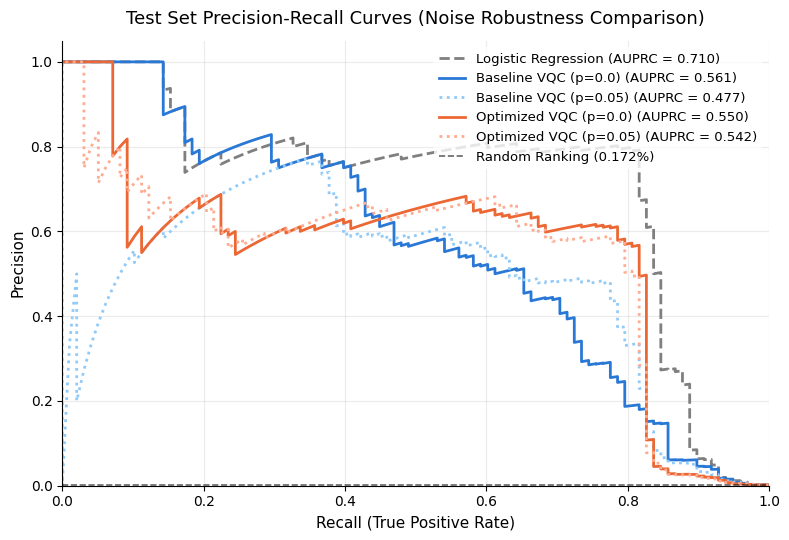

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# 1. Extragem predicțiile de test pentru ultimul seed sau un seed de referință (ex: SEED)
# (Asigură-te că variabilele de scoruri sunt calculate)
test_scores = {
    "Logistic Regression": clf.predict_proba(Zs_test)[:, 1],
    "Baseline VQC (p=0.0)": predict(Zs_test, w_base, model=fraud_probability),
    "Baseline VQC (p=0.05)": noisy_predict(Zs_test, w_base, p=0.05, circuit_fn=vqc),
    "Optimized VQC (p=0.0)": predict(Zs_test, w_opt, model=opt_fraud_probability),
    "Optimized VQC (p=0.05)": noisy_predict(Zs_test, w_opt, p=0.05, circuit_fn=opt_vqc),
}

# 2. Setări vizuale
colors = {
    "Logistic Regression": "#7f7f7f",       # Gri neutru
    "Baseline VQC (p=0.0)": "#2a78d6",      # Albastru solid
    "Baseline VQC (p=0.05)": "#90caf9",     # Albastru deschis punctat
    "Optimized VQC (p=0.0)": "#eb6834",     # Portocaliu solid
    "Optimized VQC (p=0.05)": "#ffab91",    # Portocaliu deschis punctat
}

line_styles = {
    "Logistic Regression": "--",
    "Baseline VQC (p=0.0)": "-",
    "Baseline VQC (p=0.05)": ":",
    "Optimized VQC (p=0.0)": "-",
    "Optimized VQC (p=0.05)": ":",
}

fig, ax = plt.subplots(figsize=(8, 5.5))

# 3. Trasarea curbelor pentru fiecare model
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    ax.plot(
        recall,
        precision,
        color=colors[name],
        linestyle=line_styles[name],
        linewidth=2,
        label=f"{name} (AUPRC = {ap:.3f})"
    )

# 4. Linia de referință aleatorie (Random Guess = Fraud Rate)
fraud_baseline = y_test.mean()
ax.axhline(
    y=fraud_baseline,
    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.6,
    label=f"Random Ranking ({fraud_baseline:.3%})"
)

# 5. Ajustări estetice
ax.set_xlabel("Recall (True Positive Rate)", fontsize=11)
ax.set_ylabel("Precision", fontsize=11)
ax.set_title("Test Set Precision-Recall Curves (Noise Robustness Comparison)", fontsize=13, pad=12)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", fontsize=9.5)

plt.tight_layout()
plt.show()

In [22]:
def gate_counts(circuit_fn, *args, n_wires=N_QUBITS):
    '''Numărul de porți native din circuit descompuse în setul hardware.'''
    dev = qml.device("default.qubit", wires=n_wires)
    
    def full():
        circuit_fn(*args)
        return qml.state()
        
    decomposed_qnode = qml.transforms.decompose(
        qml.QNode(full, dev), 
        gate_set=NATIVE_GATES
    )
    resources = qml.specs(decomposed_qnode)()["resources"]
    return dict(resources.gate_types), sum(resources.gate_types.values())

In [23]:
# 1. Exemple dummy pentru descompunerea circuitului
dummy_x = torch.tensor(Z_bal[0])
dummy_w_base = init_weights(SEED)
dummy_w_opt = opt_init_weights(SEED)

# 2. Numărarea porților pentru ambele circuite
base_gate_dict, total_gates_base = gate_counts(vqc, dummy_x, dummy_w_base)
opt_gate_dict, total_gates_opt = gate_counts(opt_vqc, dummy_x, dummy_w_opt)

# Numărul de CNOT-uri izolat (cele mai zgomotoase porți pe hardware real)
cnot_base = base_gate_dict.get("CNOT", 0)
cnot_opt = opt_gate_dict.get("CNOT", 0)

print("Detaliu porți Baseline:", base_gate_dict)
print("Detaliu porți Optimizat:", opt_gate_dict)

Detaliu porți Baseline: {'Hadamard': 8, 'RZ': 36, 'CNOT': 33, 'RY': 16}
Detaliu porți Optimizat: {'Hadamard': 4, 'RZ': 15, 'CNOT': 9, 'RY': 8}


In [24]:
n_params_base = (ANSATZ_REPS + 1) * N_QUBITS * 2        # 32
n_params_opt = (OPT_ANSATZ_REPS + 1) * N_QUBITS * 2     # 16

n_train_samples = len(Z_bal)
n_val_samples = int(len(Z_val) * 0.2)
n_test_samples = len(Z_test)

def compute_ledger(n_params, total_gates, cnot_count, noise_locs, label):
    exec_per_train = 1 + 2 * n_params
    train_execs = EPOCHS * n_train_samples * exec_per_train
    val_execs = EPOCHS * n_val_samples
    test_execs = n_test_samples
    total_execs = train_execs + val_execs + test_execs
    total_shots = total_execs * SHOTS_PER_EXECUTION
    
    return {
        "Model": label,
        "Trainable Params": n_params,
        "Total Native Gates": total_gates,
        "CNOT Gates": cnot_count,
        "Noise Locations": noise_locs,
        "Train Executions": train_execs,
        "Val Executions": val_execs,
        "Test Executions": test_execs,
        "Total Executions": total_execs,
        "Total Shots (1024/exec)": total_shots,
    }

# Calculăm noise locations
locs_base = noise_locations(vqc, dummy_x, dummy_w_base)
locs_opt = noise_locations(opt_vqc, dummy_x, dummy_w_opt)

ledger_df = pd.DataFrame([
    compute_ledger(n_params_base, total_gates_base, cnot_base, locs_base, "Baseline VQC"),
    compute_ledger(n_params_opt, total_gates_opt, cnot_opt, locs_opt, "Optimized VQC (Frugal)")
])

print("\n--- HARDWARE & COMPLEXITY COST LEDGER ---")
print(ledger_df.map(lambda v: f"{v:,}" if isinstance(v, (int, float)) else v).to_string(index=False))


--- HARDWARE & COMPLEXITY COST LEDGER ---
                 Model Trainable Params Total Native Gates CNOT Gates Noise Locations Train Executions Val Executions Test Executions Total Executions Total Shots (1024/exec)
          Baseline VQC               32                 93         33             126        1,150,500        341,760          56,962        1,549,222           1,586,403,328
Optimized VQC (Frugal)               16                 36          9              45          584,100        341,760          56,962          982,822           1,006,409,728
